In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_PATH = "/content/drive/MyDrive/Fraud_Project"

print("Project path exists:", os.path.exists(BASE_PATH))

Project path exists: True


In [ ]:
results = [
    # Experiment, Model, Precision, Recall, F1, ROC-AUC, PR-AUC
    ["E1", "XGBoost", 0.0175, 0.1875, 0.0321, 0.5220, 0.01365],
    ["E1", "LightGBM", 0.0139, 0.0781, 0.0236, 0.5264, 0.01181],
    ["E1", "MLP", 0.0286, 0.2344, 0.0510, 0.5588, 0.02692],

    ["E2", "TF-IDF + Logistic Regression", 0.0309, 0.3438, 0.0566, 0.7300, 0.03210],
    ["E2", "TF-IDF + MLP", 0.0317, 0.0625, 0.0421, 0.6491, 0.01980],

    ["E3", "Hybrid Logistic Regression", 0.0426, 0.1250, 0.0635, 0.5209, 0.01610],
    ["E3", "Hybrid MLP", 0.0258, 0.1875, 0.0454, 0.6840, 0.02517],
]

results_df = pd.DataFrame(
    results,
    columns=[
        "Experiment",
        "Model",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC",
        "PR_AUC"
    ]
)

display(results_df)

,Experiment,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,E1,XGBoost,0.0175,0.1875,0.0321,0.5220,0.01365
1,E1,LightGBM,0.0139,0.0781,0.0236,0.5264,0.01181
2,E1,MLP,0.0286,0.2344,0.0510,0.5588,0.02692
3,E2,TF-IDF + Logistic Regression,0.0309,0.3438,0.0566,0.7300,0.03210
4,E2,TF-IDF + MLP,0.0317,0.0625,0.0421,0.6491,0.01980
5,E3,Hybrid Logistic Regression,0.0426,0.1250,0.0635,0.5209,0.01610
6,E3,Hybrid MLP,0.0258,0.1875,0.0454,0.6840,0.02517


In [ ]:
results_path = os.path.join(
    BASE_PATH,
    "Comparative_Analysis_Results.csv"
)

results_df.to_csv(results_path, index=False)

print("Results table saved to:")
print(results_path)

Results table saved to:
/content/drive/MyDrive/Fraud_Project/Comparative_Analysis_Results.csv


In [ ]:
metric_columns = [
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

comparison_table = results_df[
    ["Experiment", "Model"] + metric_columns
].copy()

display(
    comparison_table.style
    .format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    })
)

,Experiment,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,E1,XGBoost,0.0175,0.1875,0.0321,0.5220,0.0137
1,E1,LightGBM,0.0139,0.0781,0.0236,0.5264,0.0118
2,E1,MLP,0.0286,0.2344,0.0510,0.5588,0.0269
3,E2,TF-IDF + Logistic Regression,0.0309,0.3438,0.0566,0.7300,0.0321
4,E2,TF-IDF + MLP,0.0317,0.0625,0.0421,0.6491,0.0198
5,E3,Hybrid Logistic Regression,0.0426,0.1250,0.0635,0.5209,0.0161
6,E3,Hybrid MLP,0.0258,0.1875,0.0454,0.6840,0.0252


In [ ]:
experiment_summary = (
    results_df
    .groupby("Experiment")[metric_columns]
    .mean()
    .reset_index()
)

display(
    experiment_summary.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    })
)

,Experiment,Precision,Recall,F1,ROC_AUC,PR_AUC
0,E1,0.0200,0.1667,0.0356,0.5357,0.0175
1,E2,0.0313,0.2031,0.0493,0.6895,0.0260
2,E3,0.0342,0.1562,0.0544,0.6025,0.0206


In [ ]:
  best_by_experiment = []

for experiment in results_df["Experiment"].unique():
    exp_df = results_df[results_df["Experiment"] == experiment]

    for metric in metric_columns:
        idx = exp_df[metric].idxmax()

        best_by_experiment.append({
            "Experiment": experiment,
            "Metric": metric,
            "Model": results_df.loc[idx, "Model"],
            "Value": results_df.loc[idx, metric]
        })

best_metrics_df = pd.DataFrame(best_by_experiment)

display(
    best_metrics_df.style.format({
        "Value": "{:.4f}"
    })
)

,Experiment,Metric,Model,Value
0,E1,Precision,MLP,0.0286
1,E1,Recall,MLP,0.2344
2,E1,F1,MLP,0.0510
3,E1,ROC_AUC,MLP,0.5588
4,E1,PR_AUC,MLP,0.0269
5,E2,Precision,TF-IDF + MLP,0.0317
6,E2,Recall,TF-IDF + Logistic Regression,0.3438
7,E2,F1,TF-IDF + Logistic Regression,0.0566
8,E2,ROC_AUC,TF-IDF + Logistic Regression,0.7300
9,E2,PR_AUC,TF-IDF + Logistic Regression,0.0321


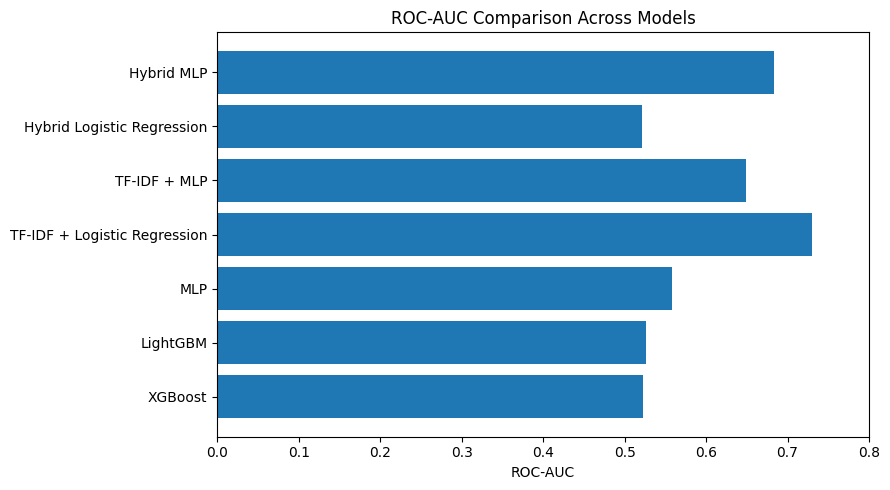

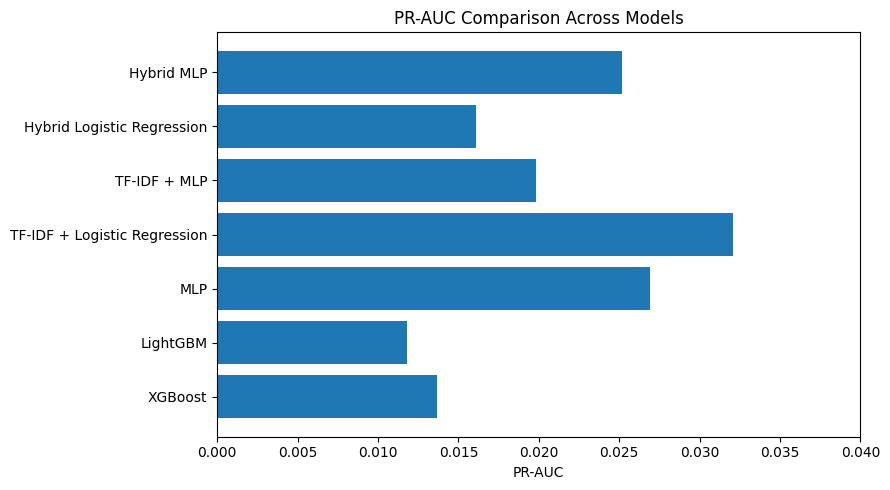

ROC-AUC figure saved to:
/content/drive/MyDrive/Fraud_Project/ROC_AUC_Comparison_Clean.png

PR-AUC figure saved to:
/content/drive/MyDrive/Fraud_Project/PR_AUC_Comparison_Clean.png


In [ ]:
# -----------------------------
# ROC-AUC figure
# -----------------------------
plt.figure(figsize=(9, 5))

plt.barh(
    results_df["Model"],
    results_df["ROC_AUC"]
)

plt.xlabel("ROC-AUC")
plt.title("ROC-AUC Comparison Across Models")
plt.xlim(0, 0.8)
plt.tight_layout()

roc_path = os.path.join(
    BASE_PATH,
    "ROC_AUC_Comparison_Clean.png"
)

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# -----------------------------
# PR-AUC figure
# -----------------------------
plt.figure(figsize=(9, 5))

plt.barh(
    results_df["Model"],
    results_df["PR_AUC"]
)

plt.xlabel("PR-AUC")
plt.title("PR-AUC Comparison Across Models")
plt.xlim(0, 0.04)
plt.tight_layout()

pr_path = os.path.join(
    BASE_PATH,
    "PR_AUC_Comparison_Clean.png"
)

plt.savefig(
    pr_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("ROC-AUC figure saved to:")
print(roc_path)

print("\nPR-AUC figure saved to:")
print(pr_path)

In [ ]:
e1_e3 = results_df[
    results_df["Experiment"].isin(["E1", "E3"])
].copy()

display(
    e1_e3.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    })
)

,Experiment,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,E1,XGBoost,0.0175,0.1875,0.0321,0.5220,0.0137
1,E1,LightGBM,0.0139,0.0781,0.0236,0.5264,0.0118
2,E1,MLP,0.0286,0.2344,0.0510,0.5588,0.0269
5,E3,Hybrid Logistic Regression,0.0426,0.1250,0.0635,0.5209,0.0161
6,E3,Hybrid MLP,0.0258,0.1875,0.0454,0.6840,0.0252


In [ ]:
mlp_comparison = results_df[
    results_df["Model"].isin(["MLP", "Hybrid MLP"])
].copy()

mlp_comparison = mlp_comparison[
    ["Experiment", "Model", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]
]

display(
    mlp_comparison.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    })
)

,Experiment,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
2,E1,MLP,0.0286,0.2344,0.0510,0.5588,0.0269
6,E3,Hybrid MLP,0.0258,0.1875,0.0454,0.6840,0.0252


In [ ]:
e1_mlp = results_df[
    (results_df["Experiment"] == "E1") &
    (results_df["Model"] == "MLP")
].iloc[0]

e3_mlp = results_df[
    (results_df["Experiment"] == "E3") &
    (results_df["Model"] == "Hybrid MLP")
].iloc[0]

change_rows = []

for metric in metric_columns:
    e1_value = e1_mlp[metric]
    e3_value = e3_mlp[metric]

    absolute_change = e3_value - e1_value

    percentage_change = (
        (absolute_change / e1_value) * 100
        if e1_value != 0 else np.nan
    )

    change_rows.append({
        "Metric": metric,
        "E1_MLP": e1_value,
        "E3_Hybrid_MLP": e3_value,
        "Absolute_Change": absolute_change,
        "Percentage_Change": percentage_change
    })

mlp_change_df = pd.DataFrame(change_rows)

display(
    mlp_change_df.style.format({
        "E1_MLP": "{:.4f}",
        "E3_Hybrid_MLP": "{:.4f}",
        "Absolute_Change": "{:+.4f}",
        "Percentage_Change": "{:+.2f}%"
    })
)

,Metric,E1_MLP,E3_Hybrid_MLP,Absolute_Change,Percentage_Change
0,Precision,0.0286,0.0258,-0.0028,-9.79%
1,Recall,0.2344,0.1875,-0.0469,-20.01%
2,F1,0.0510,0.0454,-0.0056,-10.98%
3,ROC_AUC,0.5588,0.6840,+0.1252,+22.41%
4,PR_AUC,0.0269,0.0252,-0.0017,-6.50%


In [ ]:
mlp_change_path = os.path.join(
    BASE_PATH,
    "E1_MLP_vs_E3_Hybrid_MLP_Comparison.csv"
)

mlp_change_df.to_csv(
    mlp_change_path,
    index=False
)

print("Controlled comparison saved to:")
print(mlp_change_path)

Controlled comparison saved to:
/content/drive/MyDrive/Fraud_Project/E1_MLP_vs_E3_Hybrid_MLP_Comparison.csv


In [ ]:
e2_e3_mlp = results_df[
    results_df["Model"].isin(["TF-IDF + MLP", "Hybrid MLP"])
].copy()

e2_e3_mlp = e2_e3_mlp[
    ["Experiment", "Model", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]
]

display(
    e2_e3_mlp.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    })
)

,Experiment,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
4,E2,TF-IDF + MLP,0.0317,0.0625,0.0421,0.6491,0.0198
6,E3,Hybrid MLP,0.0258,0.1875,0.0454,0.6840,0.0252


In [ ]:
e2_mlp = results_df[
    (results_df["Experiment"] == "E2") &
    (results_df["Model"] == "TF-IDF + MLP")
].iloc[0]

e3_hybrid_mlp = results_df[
    (results_df["Experiment"] == "E3") &
    (results_df["Model"] == "Hybrid MLP")
].iloc[0]

e2_e3_change_rows = []

for metric in metric_columns:
    e2_value = e2_mlp[metric]
    e3_value = e3_hybrid_mlp[metric]

    absolute_change = e3_value - e2_value

    percentage_change = (
        (absolute_change / e2_value) * 100
        if e2_value != 0 else np.nan
    )

    e2_e3_change_rows.append({
        "Metric": metric,
        "E2_TFIDF_MLP": e2_value,
        "E3_Hybrid_MLP": e3_value,
        "Absolute_Change": absolute_change,
        "Percentage_Change": percentage_change
    })

e2_e3_change_df = pd.DataFrame(e2_e3_change_rows)

display(
    e2_e3_change_df.style.format({
        "E2_TFIDF_MLP": "{:.4f}",
        "E3_Hybrid_MLP": "{:.4f}",
        "Absolute_Change": "{:+.4f}",
        "Percentage_Change": "{:+.2f}%"
    })
)

,Metric,E2_TFIDF_MLP,E3_Hybrid_MLP,Absolute_Change,Percentage_Change
0,Precision,0.0317,0.0258,-0.0059,-18.61%
1,Recall,0.0625,0.1875,+0.1250,+200.00%
2,F1,0.0421,0.0454,+0.0033,+7.84%
3,ROC_AUC,0.6491,0.6840,+0.0349,+5.38%
4,PR_AUC,0.0198,0.0252,+0.0054,+27.12%


In [ ]:
e2_e3_change_path = os.path.join(
    BASE_PATH,
    "E2_TFIDF_MLP_vs_E3_Hybrid_MLP_Comparison.csv"
)

e2_e3_change_df.to_csv(
    e2_e3_change_path,
    index=False
)

print("E2 to E3 comparison saved to:")
print(e2_e3_change_path)

E2 to E3 comparison saved to:
/content/drive/MyDrive/Fraud_Project/E2_TFIDF_MLP_vs_E3_Hybrid_MLP_Comparison.csv


In [ ]:
e1_e3_summary = mlp_change_df.copy()
e1_e3_summary["Comparison"] = "E1 MLP → E3 Hybrid MLP"

e2_e3_summary = e2_e3_change_df.copy()
e2_e3_summary["Comparison"] = "E2 TF-IDF MLP → E3 Hybrid MLP"

combined_comparison = pd.concat(
    [e1_e3_summary, e2_e3_summary],
    ignore_index=True
)

combined_comparison = combined_comparison[
    [
        "Comparison",
        "Metric",
        "Absolute_Change",
        "Percentage_Change"
    ]
]

display(
    combined_comparison.style.format({
        "Absolute_Change": "{:+.4f}",
        "Percentage_Change": "{:+.2f}%"
    })
)

,Comparison,Metric,Absolute_Change,Percentage_Change
0,E1 MLP → E3 Hybrid MLP,Precision,-0.0028,-9.79%
1,E1 MLP → E3 Hybrid MLP,Recall,-0.0469,-20.01%
2,E1 MLP → E3 Hybrid MLP,F1,-0.0056,-10.98%
3,E1 MLP → E3 Hybrid MLP,ROC_AUC,+0.1252,+22.41%
4,E1 MLP → E3 Hybrid MLP,PR_AUC,-0.0017,-6.50%
5,E2 TF-IDF MLP → E3 Hybrid MLP,Precision,-0.0059,-18.61%
6,E2 TF-IDF MLP → E3 Hybrid MLP,Recall,+0.1250,+200.00%
7,E2 TF-IDF MLP → E3 Hybrid MLP,F1,+0.0033,+7.84%
8,E2 TF-IDF MLP → E3 Hybrid MLP,ROC_AUC,+0.0349,+5.38%
9,E2 TF-IDF MLP → E3 Hybrid MLP,PR_AUC,+0.0054,+27.12%


In [ ]:
combined_path = os.path.join(
    BASE_PATH,
    "Combined_Controlled_E1_E2_E3_Comparison.csv"
)

combined_comparison.to_csv(
    combined_path,
    index=False
)

print("Combined comparison saved to:")
print(combined_path)

Combined comparison saved to:
/content/drive/MyDrive/Fraud_Project/Combined_Controlled_E1_E2_E3_Comparison.csv


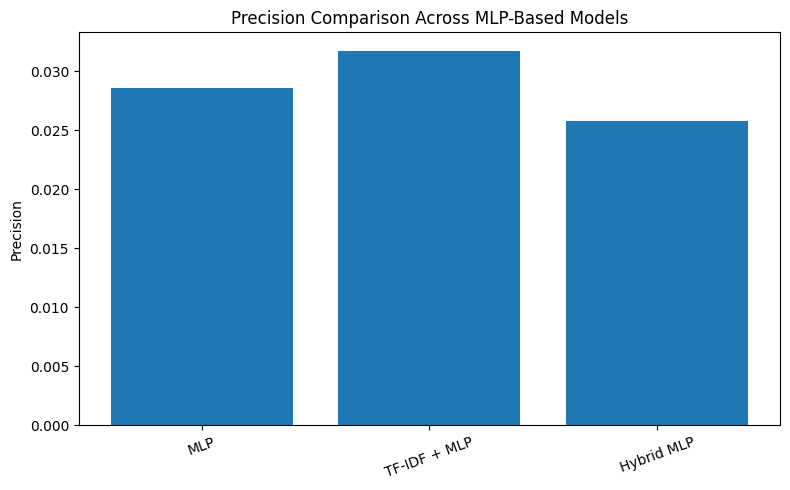

Saved: /content/drive/MyDrive/Fraud_Project/MLP_Precision_Comparison.png


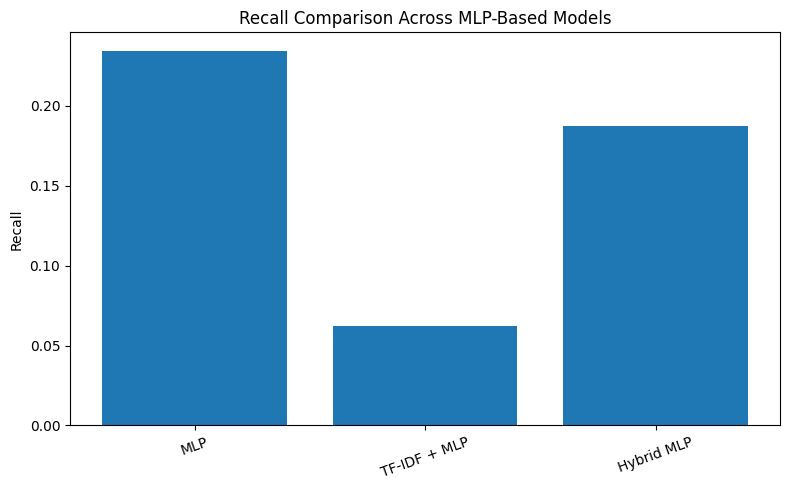

Saved: /content/drive/MyDrive/Fraud_Project/MLP_Recall_Comparison.png


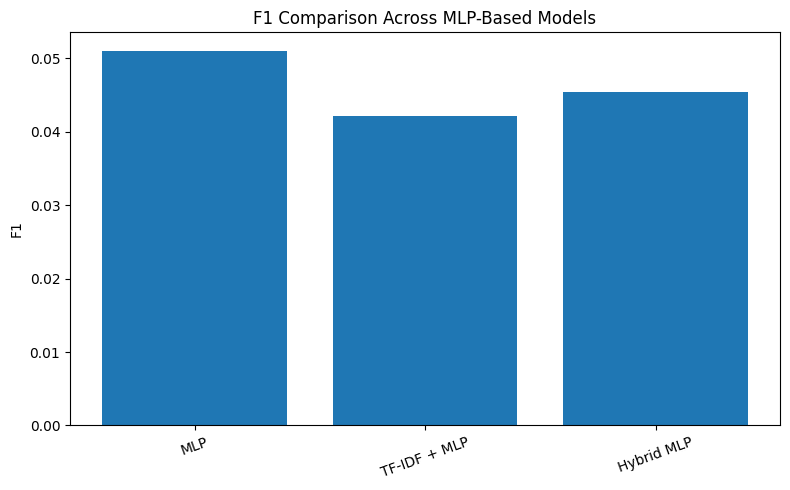

Saved: /content/drive/MyDrive/Fraud_Project/MLP_F1_Comparison.png


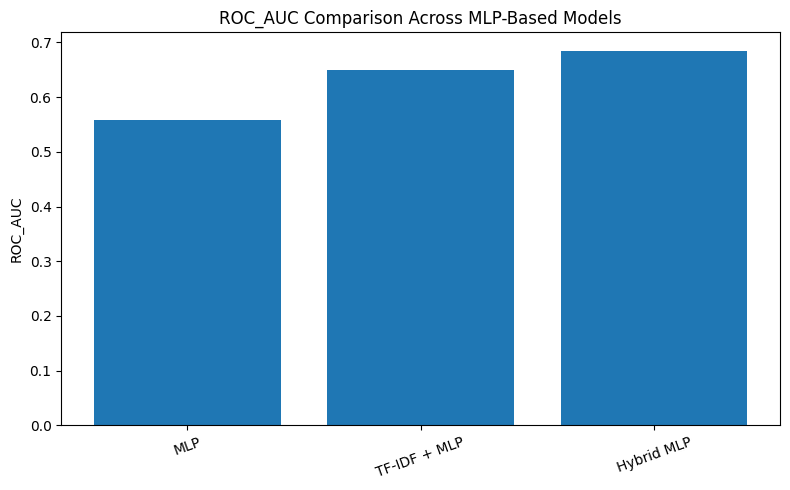

Saved: /content/drive/MyDrive/Fraud_Project/MLP_ROC_AUC_Comparison.png


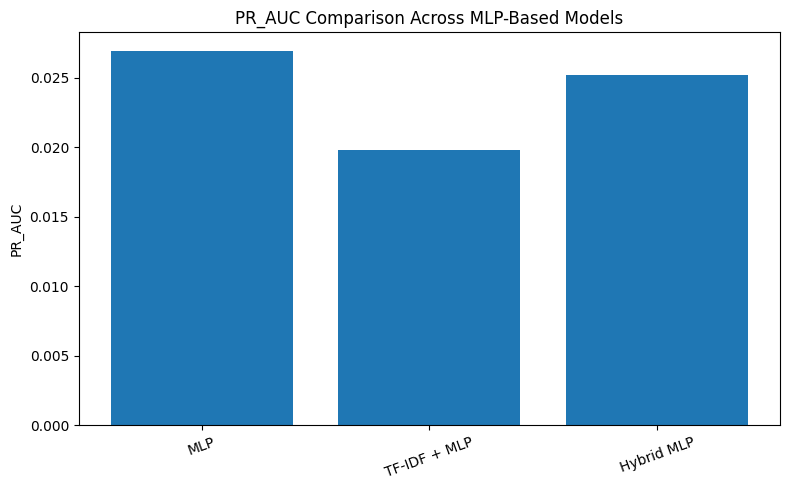

Saved: /content/drive/MyDrive/Fraud_Project/MLP_PR_AUC_Comparison.png


In [ ]:
mlp_family = results_df[
    results_df["Model"].isin([
        "MLP",
        "TF-IDF + MLP",
        "Hybrid MLP"
    ])
].copy()

metrics_to_plot = [
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

for metric in metrics_to_plot:
    plt.figure(figsize=(8, 5))

    plt.bar(
        mlp_family["Model"],
        mlp_family[metric]
    )

    plt.title(f"{metric} Comparison Across MLP-Based Models")
    plt.ylabel(metric)
    plt.xticks(rotation=20)

    plt.tight_layout()

    filename = f"MLP_{metric}_Comparison.png"
    filepath = os.path.join(BASE_PATH, filename)

    plt.savefig(
        filepath,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", filepath)

In [ ]:
mlp_plot_files = [
    "MLP_Precision_Comparison.png",
    "MLP_Recall_Comparison.png",
    "MLP_F1_Comparison.png",
    "MLP_ROC_AUC_Comparison.png",
    "MLP_PR_AUC_Comparison.png"
]

plot_check = pd.DataFrame({
    "File": mlp_plot_files,
    "Exists": [
        os.path.exists(os.path.join(BASE_PATH, f))
        for f in mlp_plot_files
    ]
})

display(plot_check)

,File,Exists
0,MLP_Precision_Comparison.png,True
1,MLP_Recall_Comparison.png,True
2,MLP_F1_Comparison.png,True
3,MLP_ROC_AUC_Comparison.png,True
4,MLP_PR_AUC_Comparison.png,True


In [ ]:
test_fraud = 64
test_nonfraud = 6121
test_total = test_fraud + test_nonfraud

fraud_prevalence = test_fraud / test_total

class_summary = pd.DataFrame({
    "Class": ["Non-Fraud", "Fraud", "Total"],
    "Count": [test_nonfraud, test_fraud, test_total],
    "Percentage": [
        test_nonfraud / test_total * 100,
        test_fraud / test_total * 100,
        100.0
    ]
})

display(
    class_summary.style.format({
        "Percentage": "{:.2f}%"
    })
)

print(f"Fraud prevalence in test set: {fraud_prevalence:.4f}")
print(f"Fraud prevalence percentage: {fraud_prevalence * 100:.2f}%")

,Class,Count,Percentage
0,Non-Fraud,6121,98.97%
1,Fraud,64,1.03%
2,Total,6185,100.00%


Fraud prevalence in test set: 0.0103
Fraud prevalence percentage: 1.03%


In [ ]:
baseline_pr = fraud_prevalence

pr_lift_df = results_df[
    ["Experiment", "Model", "PR_AUC"]
].copy()

pr_lift_df["PR_AUC_Lift"] = (
    pr_lift_df["PR_AUC"] / baseline_pr
)

pr_lift_df["PR_AUC_Above_Prevalence"] = (
    (pr_lift_df["PR_AUC"] - baseline_pr) / baseline_pr * 100
)

display(
    pr_lift_df.style.format({
        "PR_AUC": "{:.4f}",
        "PR_AUC_Lift": "{:.2f}x",
        "PR_AUC_Above_Prevalence": "{:+.2f}%"
    })
)

,Experiment,Model,PR_AUC,PR_AUC_Lift,PR_AUC_Above_Prevalence
0,E1,XGBoost,0.0137,1.32x,+31.91%
1,E1,LightGBM,0.0118,1.14x,+14.13%
2,E1,MLP,0.0269,2.60x,+160.16%
3,E2,TF-IDF + Logistic Regression,0.0321,3.10x,+210.22%
4,E2,TF-IDF + MLP,0.0198,1.91x,+91.35%
5,E3,Hybrid Logistic Regression,0.0161,1.56x,+55.59%
6,E3,Hybrid MLP,0.0252,2.43x,+143.24%


In [ ]:
pr_lift_path = os.path.join(
    BASE_PATH,
    "PR_AUC_vs_Fraud_Prevalence.csv"
)

pr_lift_df.to_csv(
    pr_lift_path,
    index=False
)

print("PR-AUC prevalence analysis saved to:")
print(pr_lift_path)

PR-AUC prevalence analysis saved to:
/content/drive/MyDrive/Fraud_Project/PR_AUC_vs_Fraud_Prevalence.csv


In [ ]:
key_results = pd.DataFrame([
    {
        "Experiment": "E1",
        "Setting": "Financial-only",
        "Best_ROC_AUC": 0.5588,
        "Best_PR_AUC": 0.0269,
        "Best_F1": 0.0510,
        "Model_for_ROC_AUC": "MLP",
        "Model_for_PR_AUC": "MLP",
        "Model_for_F1": "MLP"
    },
    {
        "Experiment": "E2",
        "Setting": "MD&A-only",
        "Best_ROC_AUC": 0.7300,
        "Best_PR_AUC": 0.0321,
        "Best_F1": 0.0566,
        "Model_for_ROC_AUC": "TF-IDF + Logistic Regression",
        "Model_for_PR_AUC": "TF-IDF + Logistic Regression",
        "Model_for_F1": "TF-IDF + Logistic Regression"
    },
    {
        "Experiment": "E3",
        "Setting": "Financial + MD&A",
        "Best_ROC_AUC": 0.6840,
        "Best_PR_AUC": 0.0252,
        "Best_F1": 0.0635,
        "Model_for_ROC_AUC": "Hybrid MLP",
        "Model_for_PR_AUC": "Hybrid MLP",
        "Model_for_F1": "Hybrid Logistic Regression"
    }
])

display(
    key_results.style.format({
        "Best_ROC_AUC": "{:.4f}",
        "Best_PR_AUC": "{:.4f}",
        "Best_F1": "{:.4f}"
    })
)

,Experiment,Setting,Best_ROC_AUC,Best_PR_AUC,Best_F1,Model_for_ROC_AUC,Model_for_PR_AUC,Model_for_F1
0,E1,Financial-only,0.5588,0.0269,0.0510,MLP,MLP,MLP
1,E2,MD&A-only,0.7300,0.0321,0.0566,TF-IDF + Logistic Regression,TF-IDF + Logistic Regression,TF-IDF + Logistic Regression
2,E3,Financial + MD&A,0.6840,0.0252,0.0635,Hybrid MLP,Hybrid MLP,Hybrid Logistic Regression


In [ ]:
final_summary_path = os.path.join(
    BASE_PATH,
    "Final_Comparative_Summary.csv"
)

key_results.to_csv(
    final_summary_path,
    index=False
)

print("Final comparative summary saved to:")
print(final_summary_path)

Final comparative summary saved to:
/content/drive/MyDrive/Fraud_Project/Final_Comparative_Summary.csv
